# Backpropagation

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
%matplotlib inline

### Derivatives 101

What is the derivative of a function? It is the slope of the function at that point, and it tells us how sensitive the output of the function is to changes in the input

In [2]:
def f(x):
  return 2*x**2 + 4*x + 2

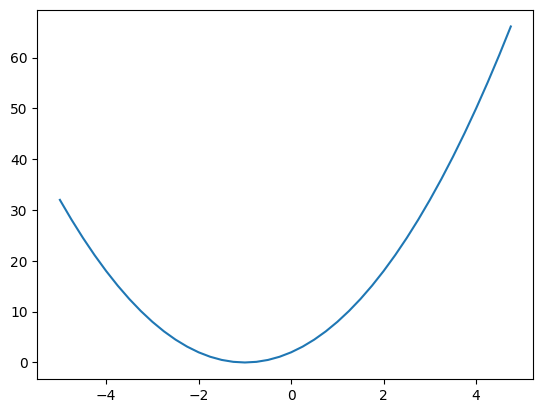

In [3]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

In [4]:
h = 0.001
x = 0
start = f(x)
end = f(x + h)
derivative = (f(x + h) - f(x)) / h


In [5]:
start, end, derivative

(2, 2.004002, 4.001999999999839)

# Partial Derivatives

We can take the derivative of a variable, wrt other variables

In [6]:
# function under inspection
def f(a, b, c):
  return a*b + c

In [7]:
a = 1
b = 2
c = 5
y1 = f(a,b,c)
y1

7

In [8]:
h = 0.01
a += h

y2 = f(a,b,c)
y2

7.02

In [9]:
#start, stop, derivative wrt a
y1, y2, ((y2 - y1) / h)

(7, 7.02, 1.9999999999999574)

Derivative wrt b should be 1 (specifically, should be a)

Derivative wrt c should be 1

## Defining Value Object

The Value object will be used as the scalar values that are put together to make up a neural network. It basically allows standard mathematical operations + contains information on what values and operations produced it

In [10]:
class Value:
  def __init__(self, data, children=(), _op='', label=''):
    self.data = data
    self.grad = 0.0
    self._backward = lambda: None
    self._prev = set(children)
    self._op = _op
    self.label = label

  def __repr__(self):
    """Returns a human readable expression of object"""
    return f"Value(data={self.data})"

  def __add__(self, other):
    """Allows for + operator to be used"""
    children = (self, other)
    label = self.label + '+' + other.label
    out = Value(self.data + other.data, children, '+', label)

    def _backward():
      self.grad = 1 * out.grad
      other.grad = 1 * out.grad

    out._backward = _backward

    return out

  def __mul__(self, other):
    """Allows for * operator to be used"""
    children = (self, other)
    label = self.label + '*' + other.label
    out = Value(self.data * other.data, children, '*', label)

    def _backward():
      self.grad = other.data * out.grad
      other.grad = self.data * out.grad

    out._backward = _backward

    return out

  def tanh(self):
    x = self.data
    t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)
    out = Value(t, (self, ), 'tanh')

    def _backward():
      self.grad = (1 - (t**2)) * out.grad

    out._backward = _backward

    return out

In [11]:
a = Value(2.0, label='a')
b = Value(5.0, label='b')
a + b

Value(data=7.0)

In [12]:
a*b

Value(data=10.0)

In [13]:
d = a*b
d._prev
d.label='d'

In [14]:
# visualization function

from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right

  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

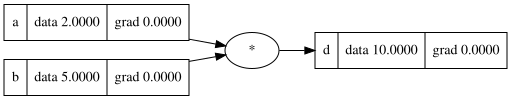

In [15]:
draw_dot(d)

## Recap

We have built out this Value object that can be operated upon, store info on how we arrived at it (operator and children), and store info on the gradients as well.
This object can be used both as the weights of a neural network, the data being passed into it, or the loss function being optimized. The goal is to, starting from the output, backpropagate using the chain rule, to slowly update the weights to minimize the loss

## A More Complex Example

In [16]:
x1 = Value(-2.0, label = 'x1')
x2 = Value(5.0, label = 'x2')
w1 = x1*x2
w1.label = 'w1'
w2 = Value(1.0, label = 'w2')
L = w1+w2
L.label ='L'

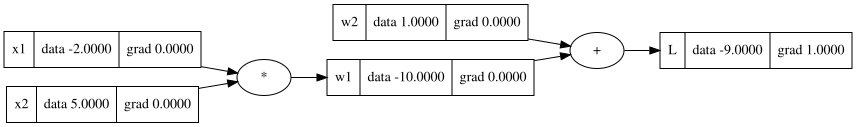

In [17]:
L.grad = 1 # a given, dL/dL = 1 always
draw_dot(L)

In [18]:
def derivative_L_wrt_x1():
  h = 0.001

  x1 = Value(-2.0, label = 'x1')
  x2 = Value(5.0, label = 'x2')
  w1 = x1*x2
  w1.label = 'w1'
  w2 = Value(1.0, label = 'w2')
  L = w1+w2
  L.label ='L'
  L = L.data

  x1 = Value(-2.0+h, label = 'x1')
  x2 = Value(5.0, label = 'x2')
  w1 = x1*x2
  w1.label = 'w1'
  w2 = Value(1.0, label = 'w2')
  L2 = w1+w2
  L2.label ='L2'
  L2 = L2.data

  print(L, L2, ((L2 - L)/h))

derivative_L_wrt_x1()
# The true derivative of L wrt x1 is 5 (x2)

-9.0 -8.995000000000001 4.999999999999005


Now, we want to get the derivatives of L with respect to all these Values. How do we get them?

## Derivatives and Chain Rule

Don't need to delve too much into this:

$dL / dw_1$ = $dL / dw_2$ = 1

$dL / dx_2$ = $dL / dw_1$ * $dw_1 / dx_2 = 1 * x_1 = -2$


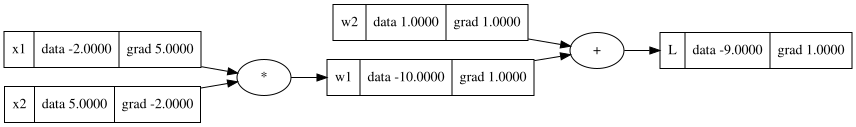

In [19]:
x1.grad = 5
x2.grad = -2
w1.grad = w2.grad = 1
draw_dot(L)

Important note: The derivative tells us how y changes with respect to x. Conversely, it tells us how nudging x would change y:

1. If dy/dx is +ve, increasing x increases y. If -ve, decreasing x increases y

2. The magnitude of the derivative tells us how much y moves in the direction of the sign, e.g: if the derivative is 100, y moves a lot (the slope is steep)



With the information given, we can increase L by moving all its children in the direction of their gradient.


## Step 2: Building a 'Neuron'

What is a neuron? A neuron is a combination of weight, bias, and function.

A neuron takes in some input x, and returns $f(wx + b)$

f tends to be a sigmoid, ReLU, tanh, etc. function to add nonlinearity.

Neurons make up the neural network: they take in inputs (either from data or from child nodes), modify it, pass it on, and slowly move their weights/biases with backpropagation.

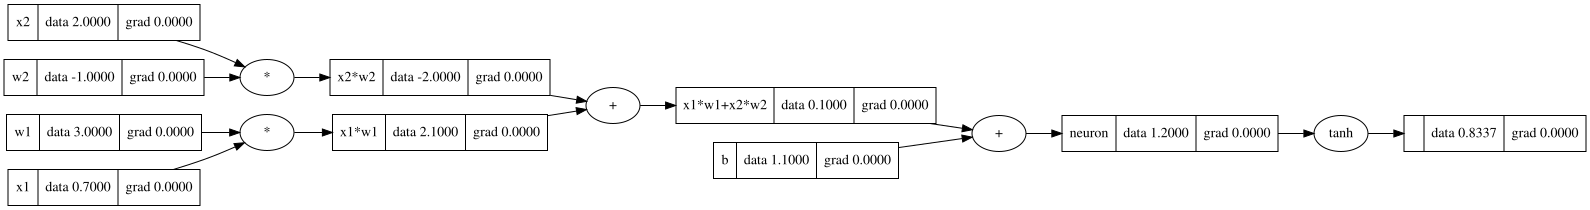

In [20]:
# inputs of the neuron

x1 = Value(0.7, label='x1')
x2 = Value(2, label='x2')

# weights

w1 = Value(3, label='w1')
w2 = Value(-1, label='w2')

# bias

b = Value(1.1, label='b')

#The neuron

x1w1 = x1*w1
x2w2 = x2*w2
XW = x1w1 + x2w2
neuron = XW + b
neuron.label = 'neuron'
o = neuron.tanh()

draw_dot(o)


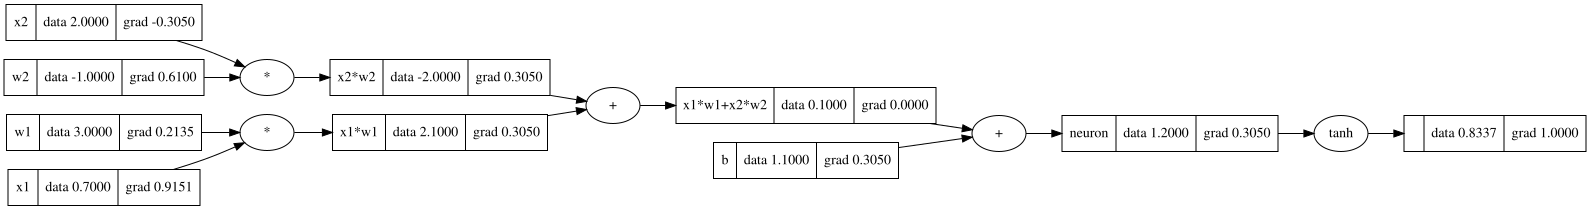

In [21]:
# setting up backpropagation manually

o.grad = 1 #output, all .grad's are with respect to o

# o = tan(h)
#do/dn = 1 - tan(h)**2 = 1 - o**2

neuron.grad = 1 - (o.data**2)

XW = b.grad = (1 * neuron.grad)

x1w1.grad = x2w2.grad = XW

x1.grad = w1.data * x1w1.grad
w1.grad = x1.data * x1w1.grad
x2.grad = w2.data * x2w2.grad
w2.grad = x2.data * x2w2.grad

draw_dot(o)

Generalizing this:

The derivative of every Value x wrt o =

local derivative of f(x) wrt x * derivative of o wrt to f(x)

= local derivative * f(x).grad

Now we want to codify this: the backward propagation should be

1. a function of a Value object
2. that is able to compute its own derivative wrt o
3. with information on its own local derivative + derivative of parent node

In [22]:
# Try again, no manual setup

# inputs of the neuron

x1 = Value(0.7, label='x1')
x2 = Value(2, label='x2')

# weights

w1 = Value(3, label='w1')
w2 = Value(-1, label='w2')

# bias

b = Value(1.1, label='b')

#The neuron

x1w1 = x1*w1
x2w2 = x2*w2
XW = x1w1 + x2w2
neuron = XW + b
neuron.label = 'neuron'
o = neuron.tanh()
o.grad = 1


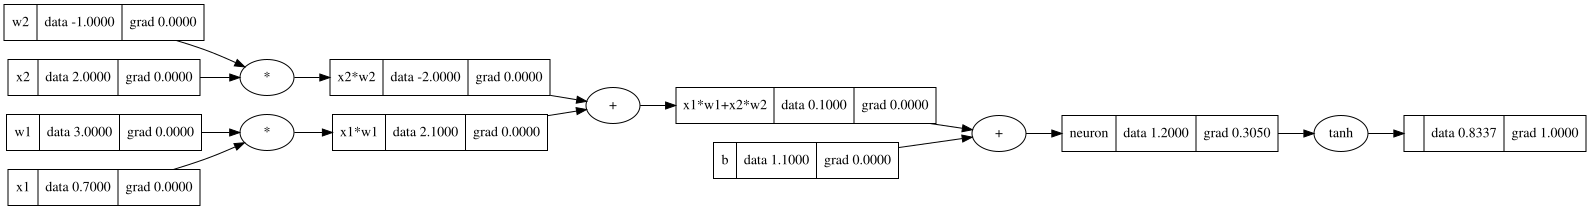

In [23]:
o._backward()

draw_dot(o)

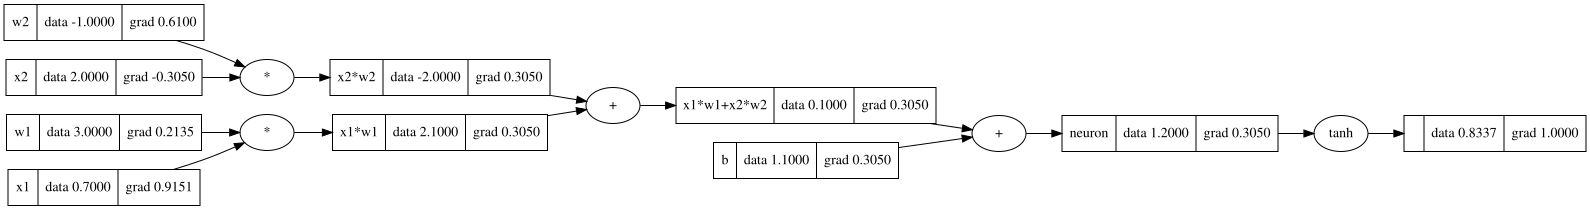

In [24]:
neuron._backward()
XW._backward()
b._backward()
x1w1._backward()
x2w2._backward()
x1._backward()
x2._backward()
w1._backward()
w2._backward()

draw_dot(o)

Looks good! Now, we just want to be able to backpropagate through the tree by calling backward at o

In [25]:
def topological_sort(root): # a method to arrange a tree such that all dependencies of a node are solved before
                           # the node itself is processed
  nodes = []
  visited = set()

  def build_tree(root):
    if root not in visited:
      visited.add(root)

      for child in root._prev:
        build_tree(child)

      nodes.append(root)

  build_tree(root)

  return nodes

In [26]:
order = topological_sort(o) # we will use this function to ensure that when calling _backward, the gradients required are always available

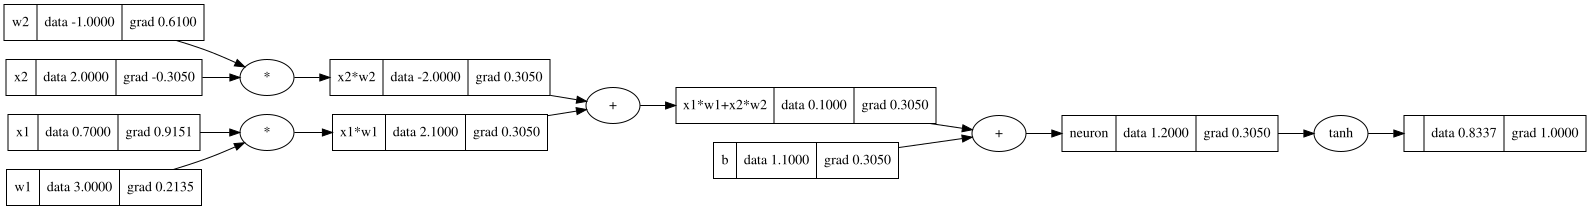

In [27]:
# Try again, no manual setup

# inputs of the neuron

x1 = Value(0.7, label='x1')
x2 = Value(2, label='x2')

# weights

w1 = Value(3, label='w1')
w2 = Value(-1, label='w2')

# bias

b = Value(1.1, label='b')

#The neuron

x1w1 = x1*w1
x2w2 = x2*w2
XW = x1w1 + x2w2
neuron = XW + b
neuron.label = 'neuron'
o = neuron.tanh()
o.grad = 1

order = topological_sort(o)

for node in reversed(order):
  node._backward()

draw_dot(o)

In [28]:
class Value:
  """Updated _backward function to accumulate backprop gradients"""
  def __init__(self, data, children=(), _op='', label=''):
    self.data = data
    self.grad = 0.0
    self._backward = lambda: None
    self._prev = set(children)
    self._op = _op
    self.label = label

  def backward(self): # new function implementing that logic
    nodes = []
    visited = set()

    def build_tree(root):
      if root not in visited:
        visited.add(root)

        for child in root._prev:
          build_tree(child)

        nodes.append(root)

    build_tree(self)
    self.grad = 1

    for node in reversed(nodes):
      node._backward()

  def __repr__(self):
    """Returns a human readable expression of object"""
    return f"Value(data={self.data})"

  def __add__(self, other):
    """Allows for + operator to be used"""
    children = (self, other)
    label = self.label + '+' + other.label
    out = Value(self.data + other.data, children, '+', label)

    def _backward():
      self.grad += 1 * out.grad
      other.grad += 1 * out.grad

    out._backward = _backward

    return out

  def __mul__(self, other):
    """Allows for * operator to be used"""
    children = (self, other)
    label = self.label + '*' + other.label
    out = Value(self.data * other.data, children, '*', label)

    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad

    out._backward = _backward

    return out

  def tanh(self):
    x = self.data
    t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)
    out = Value(t, (self, ), 'tanh')

    def _backward():
      self.grad += (1 - (t**2)) * out.grad

    out._backward = _backward

    return out

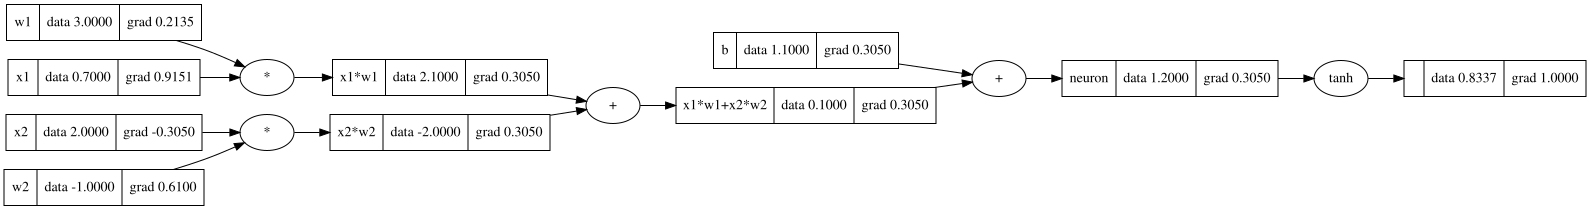

In [29]:
x1 = Value(0.7, label='x1')
x2 = Value(2, label='x2')

# weights

w1 = Value(3, label='w1')
w2 = Value(-1, label='w2')

# bias

b = Value(1.1, label='b')

#The neuron

x1w1 = x1*w1
x2w2 = x2*w2
XW = x1w1 + x2w2
neuron = XW + b
neuron.label = 'neuron'
o = neuron.tanh()
o.grad = 1

o.backward()

draw_dot(o)

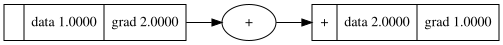

In [30]:
x1 = Value(1)
y = x1 + x1
y.backward()

draw_dot(y)

## Building a Neural Network

The Value function allows us to build a neural network, but the API for neural networks doesn't usually revolve around values, but instead uses neurons and layers.


In [31]:
class Value:

  def __init__(self, data, _children=(), _op='', label=''):
    self.data = data
    self.grad = 0.0
    self._backward = lambda: None
    self._prev = set(_children)
    self._op = _op
    self.label = label

  def __repr__(self):
    return f"Value(data={self.data})"

  def __add__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data + other.data, (self, other), '+')

    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward

    return out

  def __mul__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data * other.data, (self, other), '*')

    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad
    out._backward = _backward

    return out

  def __pow__(self, other):
    assert isinstance(other, (int, float)), "only supporting int/float powers for now"
    out = Value(self.data**other, (self,), f'**{other}')

    def _backward():
        self.grad += other * (self.data ** (other - 1)) * out.grad
    out._backward = _backward

    return out

  def __rmul__(self, other): # other * self
    return self * other

  def __truediv__(self, other): # self / other
    return self * other**-1

  def __neg__(self): # -self
    return self * -1

  def __sub__(self, other): # self - other
    return self + (-other)

  def __radd__(self, other): # other + self
    return self + other

  def tanh(self):
    x = self.data
    t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
    out = Value(t, (self, ), 'tanh')

    def _backward():
      self.grad += (1 - t**2) * out.grad
    out._backward = _backward

    return out

  def exp(self):
    x = self.data
    out = Value(math.exp(x), (self, ), 'exp')

    def _backward():
      self.grad += out.data * out.grad # NOTE: in the video I incorrectly used = instead of +=. Fixed here.
    out._backward = _backward

    return out


  def backward(self):

    topo = []
    visited = set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)

    self.grad = 1.0
    for node in reversed(topo):
      node._backward()

In [32]:
import random

class Neuron:
  def __init__(self, nin) -> None:
    self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
    self.b = Value(random.uniform(-1,1))

  def parameters(self):
    return self.w + [self.b]

  def __call__(self, x):
    total = self.b

    for wi, xi in zip(self.w, x):
      total += wi * xi

    output = total.tanh()

    return output


x = [1,1]
n = Neuron(2)
n(x)

Value(data=-0.8130169286075106)

In [33]:
class Layer:
  def __init__(self, nin, nout) -> None:
    self.neurons = [Neuron(nin) for _ in range(nout)]

  def parameters(self):
    return [p for neuron in self.neurons for p in neuron.parameters()]


  def __call__(self, x):
    outputs = [n(x) for n in self.neurons]

    return outputs[0] if len(outputs) == 1 else outputs

x = [1,1]
l = Layer(2, 2)
l(x)

[Value(data=0.2828509663947212), Value(data=-0.06745615819081112)]

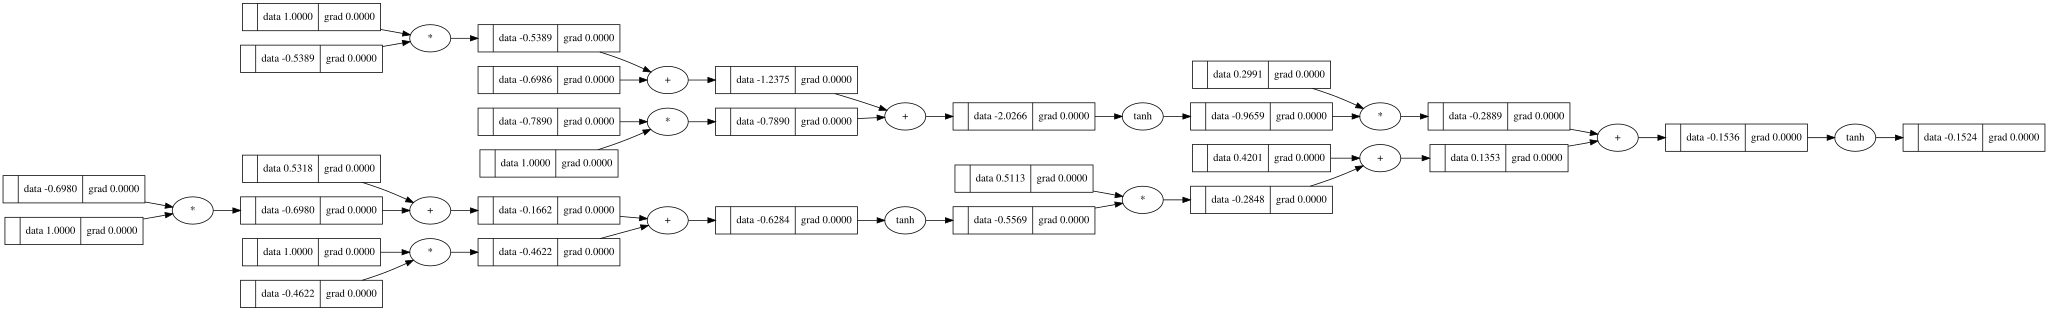

In [34]:
class MLP:
  def __init__(self, nin, layer_sizes):
    """
    nin: number of inputs
    layer_sizes: list, layer_sizes[i] = number of neurons in ith layer
    """
    sizes = [nin] + layer_sizes

    self.layers = [Layer(sizes[i], sizes[i+1]) for i in range(len(layer_sizes))]

  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]

  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)

    return x

x = [1,1]
nn = MLP(2, [2,1])
net = nn(x)
draw_dot(net)

## Backpropagation in the MLP

In [35]:
# inputs and outputs

xs = [
    [1,2,3],
    [-2,1,0],
    [5,-4,1]
    ]

ys = [1, -1, 1]
preds = [nn(x) for x in xs]
preds # current predictions

[Value(data=-0.2770313878348803),
 Value(data=0.6431197501017931),
 Value(data=-0.06050963998512669)]

y_pred differs from ys, but we want to tune the neural network such that y_pred eventually approximates ys. We do this by defining a function that measures the overall performance of the neural network in terms of approximating ys, and then backpropagating through the NN each weight wrt this value (called the loss)

In [36]:
loss = []
for y_true, y_pred in zip(ys, preds):
  error = (y_pred - y_true) ** 2

  loss.append(error)

loss = sum(loss)
loss

Value(data=5.455332375191443)

In [37]:
loss.backward()

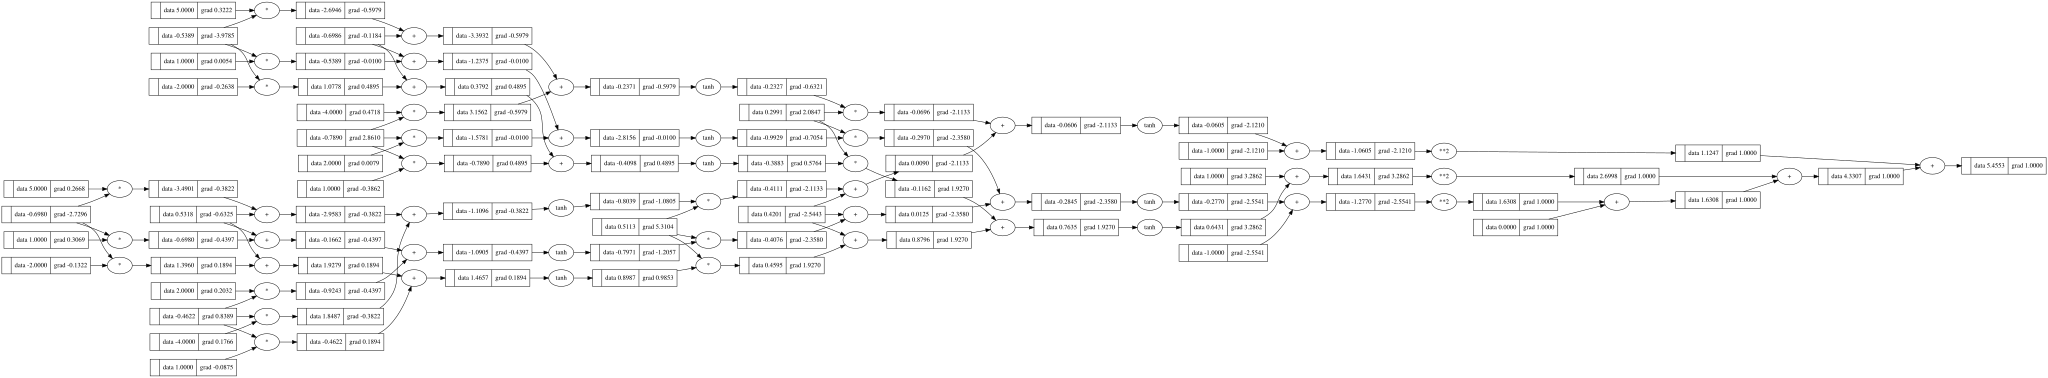

In [38]:
draw_dot(loss)

In [39]:
nn.parameters(), loss

([Value(data=-0.6980178320171135),
  Value(data=-0.4621715068899934),
  Value(data=0.5318144224108223),
  Value(data=-0.5389223621173058),
  Value(data=-0.789043081404557),
  Value(data=-0.6986239301645287),
  Value(data=0.5113179385683362),
  Value(data=0.29912657749312555),
  Value(data=0.4200862796230944)],
 Value(data=5.455332375191443))

In [40]:
for p in nn.parameters():
  p.data += -0.01 * p.grad

def loss_function(ys, preds):
  loss = []
  for y_true, y_pred in zip(ys, preds):
    error = (y_pred - y_true) ** 2

    loss.append(error)

  loss = sum(loss)
  return loss

preds = [nn(x) for x in xs]
loss = loss_function(ys, preds) # reduced from 36

In [41]:
# iterating this process
count = 0

while loss.data > 0.0001:
  #for p in nn.parameters():
  #  p.grad = 0

  count += 1
  loss.backward()

  for p in nn.parameters():
    p.data += -0.5 * p.grad
    p.grad = 0

  preds = [nn(x) for x in xs]

  loss = loss_function(ys, preds)

  print(count, loss.data)


Streaming output truncated to the last 5000 lines.
6903 3.999966500915451
6904 3.999966490610543
6905 3.9999664803017168
6906 3.99996646998897
6907 3.9999664596722995
6908 3.9999664493517026
6909 3.9999664390271765
6910 3.9999664286987184
6911 3.9999664183663244
6912 3.9999664080299913
6913 3.9999663976897155
6914 3.999966387345496
6915 3.999966376997328
6916 3.9999663666452085
6917 3.999966356289136
6918 3.999966345929106
6919 3.999966335565116
6920 3.9999663251971627
6921 3.9999663148252425
6922 3.9999663044493534
6923 3.9999662940694907
6924 3.9999662836856533
6925 3.999966273297836
6926 3.999966262906039
6927 3.999966252510255
6928 3.9999662421104833
6929 3.99996623170672
6930 3.9999662212989646
6931 3.99996621088721
6932 3.9999662004714556
6933 3.999966190051697
6934 3.9999661796279318
6935 3.999966169200157
6936 3.9999661587683697
6937 3.999966148332565
6938 3.9999661378927422
6939 3.9999661274488965
6940 3.9999661170010254
6941 3.9999661065491265
6942 3.999966096093195
6943 3.99

In [42]:
preds, ys

([Value(data=0.994397200714346),
  Value(data=-0.9917210831564747),
  Value(data=0.9999999333214796)],
 [1, -1, 1])

In [43]:
nn.parameters()

[Value(data=3.187849519920382),
 Value(data=1.0100629277257314),
 Value(data=2.2948901361491707),
 Value(data=3.1190462664943306),
 Value(data=-3.3775885204784566),
 Value(data=-0.6019134301868708),
 Value(data=2.8449866965231694),
 Value(data=2.836014848428025),
 Value(data=2.927263513415659)]